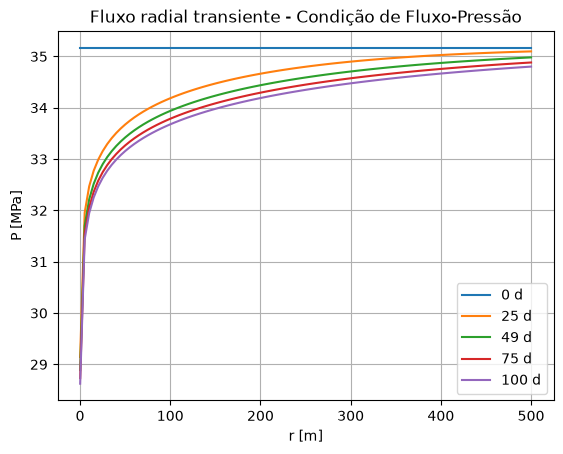

In [1]:
from pathlib import Path
import sys

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt

from analytical.radial_1d import radial_trans_1d_FP


# parameters

p0 = 35.17e6            # pressão inicial [Pa]
qw = 1.412e-3           # vazão  volumétrica no reservatório [m³/s]
h = 37                   # espessura [m]
k = 1.461e-14       # permeabilidade [m²]  =  14.8 mD
re = 500                  # raio externo [m]
rw = 0.125                  # raio do poço [m]
phi = 0.21               # porosidade [-]
ct = 1.448e-9       # compressibilidade total [1/Pa]
mu = 1.82e-3               # viscosidade [Pa.s] 
t_h = 100 # tempo [d]
t_final = t_h*86400        # tempo [s]


r, t, R, T, P = radial_trans_1d_FP(p0, qw, h, k, phi, ct, mu, t_final, rw, re)

# P em função de r

tempos_escolhidos = np.linspace(0, t_h, 5)  # dias

for tempo in tempos_escolhidos:

    t_escolhido = tempo * 86400

    indice_t = np.argmin(np.abs(t - t_escolhido))

    plt.plot(r, P[indice_t, :] / 1e6, label=f'{t[indice_t]/86400:.0f} d')

plt.xlabel('r [m]')
plt.ylabel('P [MPa]')
plt.title('Fluxo radial transiente - Condição de Fluxo-Pressão')

plt.legend()
plt.grid()

plt.savefig(RESULTS_DIR / 'fluxo_radial_transiente.pdf',
    dpi=300,
    bbox_inches='tight'
)

plt.show()
